# 04 — PyTorch TabularMLP (Auto CPU/GPU, `Unknown=0`, Unweighted Loss) & 3-Model Comparison (`P1-B4`)

- Trains `TabularMLP` on `Train (2013B+2013J)` with Early Stopping (`patience=5`) strictly on `val_select (60% of 2014B)`.
- Keeps `val_calib (40% of 2014B)` and `test_locked (2014J)` 100% untouched.
- Verifies exact match against `reports/metrics_val.json` and displays the 3-model comparison & `reports/figures/learning_curve.png`.

=== 3-Model Comparison on val_select (T=28 Operational, 2014J Locked) ===


,n,positive_rate,pr_auc,roc_auc,brier_score
logistic_regression,3905.0,0.4843,0.7815,0.7791,0.1911
lightgbm,3905.0,0.4843,0.7871,0.7842,0.188
tabular_mlp,3905,0.4843,0.7695,0.7689,0.1955



=== TabularMLP Training Summary ===
{
  "device_used": "cpu",
  "best_epoch": 2,
  "epochs_run": 7,
  "best_val_loss": 0.57402,
  "hidden_dims": [
    128,
    64
  ],
  "dropout": 0.2,
  "norm_type": "layernorm",
  "loss_function": "BCEWithLogitsLoss (unweighted \u2014 avoids class-reweighting prior-odds shift; post-hoc calibration & thresholding handled separately in P1-B5)",
  "optimizer": "AdamW(lr=1e-3, weight_decay=1e-4)",
  "early_stopping_patience": 5,
  "checkpoint_path": "artifacts/tabular_mlp_best.pt (gitignored)",
  "learning_curve_path": "learning_curve.png",
  "test_2014j_untouched": true
}


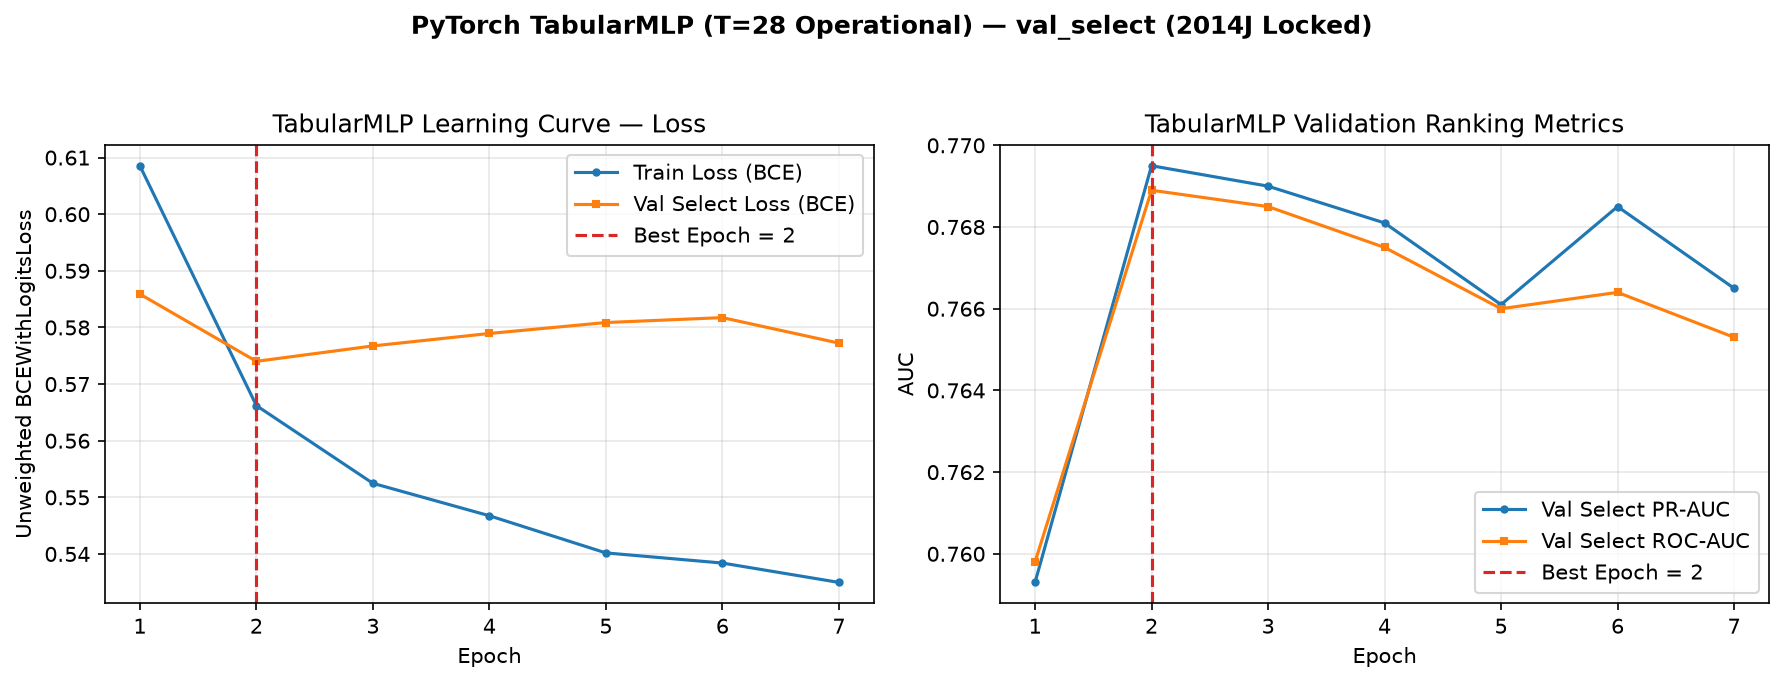

In [1]:
import json
import shutil
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from oulad.config import FIGURES_DIR, PROCESSED_DIR, REPORTS_DIR, SEED
from oulad.train_torch import run_p1_b4_torch_suite

with tempfile.TemporaryDirectory() as tmpdir:
    tmp = Path(tmpdir)
    (tmp / "reports").mkdir(parents=True, exist_ok=True)
    shutil.copy2(REPORTS_DIR / "metrics_val.json", tmp / "reports" / "metrics_val.json")
    metrics_val = run_p1_b4_torch_suite(
        processed_dir=PROCESSED_DIR,
        reports_dir=tmp / "reports",
        figures_dir=tmp / "figures",
        artifacts_dir=tmp / "artifacts",
        seed=SEED,
        prefer_cuda=False,
    )

assert metrics_val["tabular_mlp_training_info"]["test_2014j_untouched"] is True
committed_val = json.loads((REPORTS_DIR / "metrics_val.json").read_text(encoding="utf-8"))
assert metrics_val["models_val_select_t28_operational"]["tabular_mlp"] == (
    committed_val["models_val_select_t28_operational"]["tabular_mlp"]
)

comp_df = pd.DataFrame(metrics_val["models_val_select_t28_operational"]).T
print("=== 3-Model Comparison on val_select (T=28 Operational, 2014J Locked) ===")
display(comp_df[["n", "positive_rate", "pr_auc", "roc_auc", "brier_score"]])
print("\n=== TabularMLP Training Summary ===")
print(json.dumps(metrics_val["tabular_mlp_training_info"], indent=2))
display(Image(filename=str(FIGURES_DIR / "learning_curve.png")))